In [1]:
import torch
from matplotlib import pyplot as pyplot
from matplotlib import cm
import numpy as np 
import pandas as pd

from model import VAE
from utils import EarlyStop
import tqdm
import time

ModuleNotFoundError: No module named 'model'

In [2]:
fulldata = pd.read_csv('/Users/ethan/Dropbox (MIT)/Lab/lda_implementations/test_data/core3_dropNA.csv')

markers = fulldata.iloc[:, 6:]

fulldata.head()

,Unnamed: 0,:cell_id:cell_id,:X:X,:Y:Y,ClusterID,cell type,:Cyc_1_ch_2:Vimentin,:Cyc_1_ch_3:CD19,:Cyc_1_ch_4:CD31,:Cyc_2_ch_2:CD85j,...,:Cyc_15_ch_2:CD45RA,:Cyc_15_ch_3:CD90,:Cyc_15_ch_4:CD127,:Cyc_16_ch_3:CD278,:Cyc_16_ch_4:CXCR5,:Cyc_17_ch_3:CD117,:Cyc_17_ch_4:GlucTrans,:Cyc_18_ch_3:CD5,:Cyc_18_ch_4:CD279,:Cyc_19_ch_4:CD273
0,8929,32.0,969.0,1273.0,1894.0,MBC,0.244778,0.206600,0.102856,0.197223,...,0.227067,0.037475,0.096594,0.174358,0.050581,0.139847,0.004023,0.097906,-0.001856,0.102458
1,8930,91.0,970.0,1238.0,1894.0,MBC,0.262756,0.091293,0.236858,0.110341,...,0.311252,0.497991,0.475966,0.276416,0.178007,0.293348,0.513409,0.198659,0.129850,0.349027
2,8931,306.0,1247.0,398.0,1894.0,MBC,0.922822,-0.029902,-0.200346,-0.007936,...,0.039814,0.763063,0.185649,0.166598,0.327912,0.160974,0.447965,0.100393,0.192970,0.169427
3,8932,324.0,1262.0,284.0,1894.0,MBC,-0.153389,0.890970,0.097828,1.370932,...,2.130842,0.839365,2.831473,3.580575,0.655773,2.286365,3.364556,2.036354,0.828513,2.206579
4,8933,379.0,1295.0,413.0,1894.0,MBC,-0.632779,0.130956,0.041908,-0.158522,...,-0.009384,-1.115620,0.267032,0.174526,-0.103680,-0.041138,0.022429,-0.569168,-0.116524,0.065628


In [3]:
np.save('./core3_markers_dropna.npy', markers.to_numpy())

In [4]:
markers.to_numpy().shape

(27877, 52)

## Train VAE (skip if pre-trained)

In [5]:
!python train_vae.py

VAE(
  (encoder): Encoder(
    (encode): Sequential(
      (0): Linear(in_features=52, out_features=62, bias=True)
      (1): BatchNorm1d(62, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Linear(in_features=62, out_features=52, bias=True)
      (4): BatchNorm1d(52, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): Sigmoid()
    )
    (calculate_mean): MLP(
      (mlp): Sequential(
        (Linear_0): Linear(in_features=52, out_features=128, bias=True)
        (BatchNorm_0): BatchNorm1d(128, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        (ReLu_0): ReLU(inplace=True)
        (Dropout_0): Dropout(p=0.1, inplace=False)
        (Linear_1): Linear(in_features=128, out_features=128, bias=True)
        (BatchNorm_1): BatchNorm1d(128, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        (ReLu_1): ReLU(inplace=True)
        (Dropout_1): Dropout(p=0.1, inplace=False)
 

### Instantiate VAE

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

net = VAE((1, 52), latent_size = 17)
checkpoint = torch.load("VAE.pt", map_location = device)
net.load_state_dict(checkpoint["net"])
net.to(device)
net.eval()

VAE(
  (encoder): Encoder(
    (encode): Sequential(
      (0): Linear(in_features=52, out_features=62, bias=True)
      (1): BatchNorm1d(62, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Linear(in_features=62, out_features=52, bias=True)
      (4): BatchNorm1d(52, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): Sigmoid()
    )
    (calculate_mean): MLP(
      (mlp): Sequential(
        (Linear_0): Linear(in_features=52, out_features=128, bias=True)
        (BatchNorm_0): BatchNorm1d(128, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        (ReLu_0): ReLU(inplace=True)
        (Dropout_0): Dropout(p=0.1, inplace=False)
        (Linear_1): Linear(in_features=128, out_features=128, bias=True)
        (BatchNorm_1): BatchNorm1d(128, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        (ReLu_1): ReLU(inplace=True)
        (Dropout_1): Dropout(p=0.1, inplace=False)
 

### load data for evaluation

In [8]:
import evaluate as eval 

In [9]:
data = np.load('/Users/ethan/Dropbox (MIT)/Lab/lda_implementations/vae_slda/core3_markers_dropna.npy')
test_frac = 0.15
test_size = int(np.round(test_frac * data.shape[0]))
data = torch.tensor(data, dtype=torch.float32)
dataset = torch.utils.data.TensorDataset(data)
test_data, train_data = torch.utils.data.random_split(dataset, [test_size, data.shape[0]-test_size])
print(test_size)

4182


### generate data from VAE

In [10]:
with torch.no_grad():
    X_hat = net.generate(batch_size=data.shape[0]-test_size)

In [11]:
X, = train_data[:][:]
assert X.shape == X_hat.shape

In [12]:
eval.compare_covar_matrix(X, X_hat)

tensor(7297.7617)

In [10]:
X_arr = X.cpu().detach().numpy()
corr = np.corrcoef(X_arr, rowvar=False)

In [11]:
corr.shape

(52, 52)

In [10]:
np.savetxt('./X.csv', X, delimiter = ',')
np.savetxt('./X_hat.csv', X_hat, delimiter=',')

In [10]:
#### check if ||f(f(x))-f(x)|| << ||f(x) - x||

||f(x) - x|| =  955.5128784179688
||f(f(x)) - f(x)|| =  111.26441192626953
Difference: 844.2484664916992


In [11]:
# ||f(x) - x||

right = float(torch.linalg.norm(X_hat - X, ord = 2))
print('||f(x) - x|| = ', right)

# ||f(f(x)) - f(x)||
X_hat_hat, mean, logvar = net(X_hat)
left = float(torch.linalg.norm(X_hat_hat - X_hat, ord = 2))
print('||f(f(x)) - f(x)|| = ', left)

dif = right - left
print('Difference:' , dif)

In [119]:
corr_x = np.corrcoef(X_arr, rowvar=False)
corr_xhat = np.corrcoef(X_hat.numpy(), rowvar=False)

NameError: name 'corr_xhat' is not defined

In [13]:
torch.linalg.norm(torch.tensor(corr_xhat - corr_x), ord=2)

<Figure size 432x288 with 0 Axes>

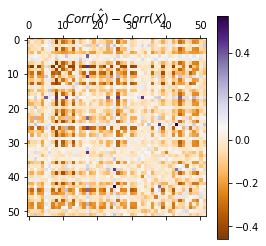

In [14]:
import matplotlib.pyplot as plt

<Figure size 432x288 with 0 Axes>

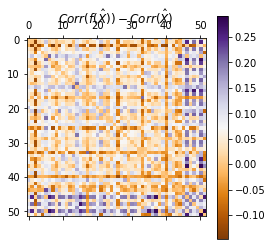

In [15]:
plt.clf()

plt.matshow(corr_xhat-corr_x, cmap='PuOr')
plt.title('$Corr(\hat{X}) - Corr(X)$')
cb = plt.colorbar()

plt.clf()

plt.matshow(np.corrcoef(X_hat_hat.detach().numpy(), rowvar=False) - corr_xhat, cmap='PuOr')
plt.title('$Corr(f(\hat{X})) - Corr(\hat{X})$')
cb = plt.colorbar()

In [11]:
### classification task

In [13]:
## Load data, make test and train set. 

from torch.utils.data import Dataset, DataLoader

class MarkerData(Dataset):
    def __init__(self, marker_arr, labels):
        self.markers = torch.tensor(marker_arr, dtype=torch.float)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        markerset = self.markers[idx, :]
        label = self.labels[idx]
        sample = {'markers': markerset, 'label' : label}
        return label, markerset


In [14]:
typenames = np.sort(fulldata['cell type'].unique())
typeIDdict = dict(zip(typenames, [k for k in range(0, len(typenames))]))
type_IDs = fulldata['cell type'].apply(lambda x: typeIDdict[x]).to_numpy()

In [15]:
data = np.load('/Users/ethan/Dropbox (MIT)/Lab/lda_implementations/vae_slda/core3_markers_dropna.npy')

dataset = MarkerData(data, type_IDs)

test_frac = 0.15
test_size = int(np.round(test_frac * data.shape[0]))
test_data, train_data = torch.utils.data.random_split(dataset, [test_size, data.shape[0]-test_size])

train_loader = DataLoader(train_data, batch_size=1024, drop_last=True)
test_loader = DataLoader(test_data, batch_size=1024, shuffle=True, drop_last=True)

In [16]:
import torch.nn as nn
import torch.nn.functional as F 

class ClassifierNet(nn.Module):
    def __init__(self):
        super(ClassifierNet, self).__init__()
        
        self.encode = nn.Sequential(nn.Linear(52, 75),
                                    nn.ReLU(inplace=True),
                                    nn.Linear(75, 50),
                                    nn.ReLU(inplace=True),
                                    nn.Linear(50, 20),
                                    nn.ReLU(inplace=True),
                                    nn.Linear(20, 8))
    
    def forward(self, x):
        x = self.encode(x)
        m = nn.Sigmoid()
        return m(x)

In [17]:
classifiernet = ClassifierNet()
save_name = "classifier.pt"
max_epochs = 200
early_stop = EarlyStop(patience = 20, save_name = save_name)

In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, classifiernet.parameters()), lr=0.01, weight_decay = 0.0001)

def adjust_lr(optimizer, decay_rate=0.95):
    for param_group in optimizer.param_groups:
        param_group['lr'] *= decay_rate


In [19]:
for epoch in range(max_epochs):

    running_loss = 0.0
    n = 0
    start = time.time()

    for i, data in tqdm.tqdm(enumerate(train_loader, 0), ncols=50):
        labels, markers = data
        n += markers.shape[0]
        
        optimizer.zero_grad()

        outputs = classifiernet(markers)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        
        '''if i % 20 == 19:    # print every 2000 mini-batches
            print('[%d, %5d] loss: %.3f' %
                (epoch + 1, i + 1, running_loss / 2000))
            running_loss = 0.0'''
    
    running_loss /= n
    print('epoch %d, train loss %.4f , time %.1f sec'
          % (epoch, running_loss, time.time() - start))   
    adjust_lr(optimizer)

    if (early_stop(running_loss, net, optimizer)):
        break


23it [00:00, 48.21it/s]
7it [00:00, 64.37it/s]epoch 0, train loss 0.0018 , time 0.5 sec
23it [00:00, 63.81it/s]
7it [00:00, 65.20it/s]epoch 1, train loss 0.0017 , time 0.4 sec
23it [00:00, 57.18it/s]
7it [00:00, 62.91it/s]epoch 2, train loss 0.0017 , time 0.4 sec
23it [00:00, 58.12it/s]
7it [00:00, 65.71it/s]epoch 3, train loss 0.0016 , time 0.4 sec
23it [00:00, 66.83it/s]
6it [00:00, 47.73it/s]epoch 4, train loss 0.0016 , time 0.3 sec
23it [00:00, 58.04it/s]
7it [00:00, 65.07it/s]epoch 5, train loss 0.0015 , time 0.4 sec
23it [00:00, 60.31it/s]
7it [00:00, 66.30it/s]epoch 6, train loss 0.0015 , time 0.4 sec
23it [00:00, 66.45it/s]
5it [00:00, 44.37it/s]epoch 7, train loss 0.0014 , time 0.3 sec
23it [00:00, 59.41it/s]
7it [00:00, 67.58it/s]epoch 8, train loss 0.0014 , time 0.4 sec
23it [00:00, 61.50it/s]
7it [00:00, 68.08it/s]epoch 9, train loss 0.0014 , time 0.4 sec
23it [00:00, 60.11it/s]
7it [00:00, 66.22it/s]epoch 10, train loss 0.0014 , time 0.4 sec
23it [00:00, 67.34it/s]
7it [00

In [20]:
correct = 0
total = 0
with torch.no_grad():
    for data in test_loader:
        labels, markers = data

        outputs = classifiernet(markers)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('NN Classifier Accuracy on Test Set: ', correct/total)

NN Classifier Accuracy on Test Set:  0.866943359375


In [21]:
# To test the reconstruction, pass known labels througth the network, 
# see if the classifier correctly labels them. 
# ex. MNIST, Pass 1s through VAE, run trained classifier on reconstruction
# and see if they are labeled ones. 

def evaluate_classifier_on_type(toi, fulldata=fulldata, return_preds = False):
    # Extract T cells
    fulldata_sub = fulldata[fulldata['cell type'] == toi]
    markers_sub = fulldata_sub.iloc[:, 6:].to_numpy()
    labels_sub = fulldata_sub['cell type'].apply(lambda x: typeIDdict[x]).to_numpy()

    markers_sub = torch.tensor(markers_sub, dtype=torch.float)
    labels_sub = torch.tensor(labels_sub, dtype = torch.double)

    # Generate T cells with VAE
    subset_hat, _, _ = net(markers_sub)

    #Test classifier accuracy on input

    correct = 0
    total = 0

    outputs = classifiernet(markers_sub)
    _, predicted = torch.max(outputs.data, 1)
    total += labels_sub.size(0)
    correct += (predicted == labels_sub).sum().item()
    predicted_x = predicted.detach().numpy()
    print('Testing ', toi)
    print("The NN Classifier Accuracy on this type is: ", correct/total, '\n')

    #Test classifer accuracy on reconstruction:
    correct = 0
    total = 0

    outputs = classifiernet(subset_hat)
    _, predicted = torch.max(outputs.data, 1)
    total += subset_hat.size(0)
    correct += (predicted == typeIDdict[toi]).sum().item()
    predicted_xhat = predicted.detach().numpy()

    print("The NN Classifier Accuracy on the reconstruction of this type is: ", correct/total, '\n')

    if return_preds:
        return predicted_x, predicted_xhat

In [22]:
for toi in typenames:
    evaluate_classifier_on_type(toi, fulldata=fulldata)

Testing  B_plasma
The NN Classifier Accuracy on this type is:  0.0 

The NN Classifier Accuracy on the reconstruction of this type is:  0.0 

Testing  Endothelial
The NN Classifier Accuracy on this type is:  0.8573046432616082 

The NN Classifier Accuracy on the reconstruction of this type is:  0.5056625141562854 

Testing  Fibroblast
The NN Classifier Accuracy on this type is:  0.63572267920094 

The NN Classifier Accuracy on the reconstruction of this type is:  0.02937720329024677 

Testing  Hepatocyte
The NN Classifier Accuracy on this type is:  0.8765230312035661 

The NN Classifier Accuracy on the reconstruction of this type is:  0.7052005943536405 

Testing  MBC
The NN Classifier Accuracy on this type is:  0.9648169591164157 

The NN Classifier Accuracy on the reconstruction of this type is:  0.9443306315133161 

Testing  Monocyte
The NN Classifier Accuracy on this type is:  0.7779744346116028 

The NN Classifier Accuracy on the reconstruction of this type is:  0.567551622418879 

In [21]:
#### Make ROC curves

In [26]:
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score

Testing  MBC
The NN Classifier Accuracy on this type is:  0.9669546628663045 

The NN Classifier Accuracy on the reconstruction of this type is:  0.9216175291707491 



In [35]:
preds_x, preds_xhat = evaluate_classifier_on_type('MBC', return_preds=True)

In [41]:
true_labels = np.ones((preds_x.shape[0],))
#np.where(preds_xhat == 4)

/Users/ethan/anaconda3/envs/pyro/lib/python3.7/site-packages/sklearn/metrics/_ranking.py:943: UndefinedMetricWarning: No negative samples in y_true, false positive value should be meaningless
  UndefinedMetricWarning)


(array([nan, nan, nan]),
 array([0.        , 0.92161753, 1.        ]),
 array([2., 1., 0.]))

In [39]:
def binarize_label(toi, labels):
    idx,  = np.where(labels == typeIDdict[toi])
    bin_arr = np.zeros(labels.shape)
    bin_arr[idx] = 1
    return bin_arr